# Kỹ thuật tạo đặc trưng (Feature Engineering) – M5 Walmart Demand Forecasting

Notebook này là bản nâng cấp toàn diện của `FeatureEnggineering.ipynb` trong quy trình MLOps:

- **Tối ưu tốc độ & bộ nhớ**: Thay thế quy trình chậm chạm (dùng `apply(lambda)` trên 46M dòng, `pivot_table` + `melt` + hàng chục lần `merge` tốn hơn 40 phút và >10GB RAM) bằng **vectorization 100%** và **Groupby Shift/Rolling trực tiếp**.
- **Chống rò rỉ dữ liệu (Data Leakage Protection)**: Mọi đặc trưng chuỗi thời gian (Lag, Rolling, EWM) đều được **dịch tối thiểu 28 ngày** (`shift >= 28`), đúng bằng khoảng thời gian cần dự báo (Horizon = 28 ngày).
- **Bổ sung đặc trưng giá**: Bổ sung các biến động giá và giá tương đối (quan sát thấy rất rõ rệt ở bước EDA nhưng notebook cũ bỏ sót).
- **Tương thích định dạng Parquet**: Đọc trực tiếp từ `data/processed/sales_clean.parquet` và xuất ra `train.parquet`, `valid.parquet` (CV), `test.parquet` chuẩn bị cho bước `Modeling.ipynb`.

## 0. Cấu hình môi trường & Thư viện

In [1]:
from pathlib import Path
import time
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Tìm thư mục gốc dự án
ROOT = Path.cwd()
while not (ROOT / "data" / "processed").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA = ROOT / "data"
PROCESSED = DATA / "processed"

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)
print("Thư mục dự án:", ROOT)
print("Pandas version:", pd.__version__)

Thư mục dự án: C:\Users\Dell\School\DoAnChuyenNganh
Pandas version: 3.0.6


## 1. Đọc dữ liệu sạch (`sales_clean.parquet`)

In [2]:
t0 = time.time()
df = pd.read_parquet(PROCESSED / "sales_clean.parquet")
# Sắp xếp đúng thứ tự thời gian theo từng chuỗi
df = df.sort_values(["id", "d_num"]).reset_index(drop=True)

print(f"Dữ liệu ban đầu: {len(df):,} dòng x {df.shape[1]} cột")
print(f"Bộ nhớ tiêu thụ: {df.memory_usage(deep=True).sum() / 1024**2:.1f} MB")
print(f"Thời gian nạp: {time.time() - t0:.2f}s")
df.head(3)

Dữ liệu ban đầu: 4,788,267 dòng x 20 cột
Bộ nhớ tiêu thụ: 164.7 MB
Thời gian nạp: 0.97s


,id,item_id,dept_id,cat_id,store_id,state_id,sales,d_num,date,wm_yr_wk,weekday,wday,month,year,event_name_1,event_type_1,event_name_2,event_type_2,snap,sell_price
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,897,2013-07-13,11325,Saturday,1,7,2013,NoEvent,NoEvent,NoEvent,NoEvent,0,9.58
1,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,898,2013-07-14,11325,Sunday,2,7,2013,NoEvent,NoEvent,NoEvent,NoEvent,0,9.58
2,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,899,2013-07-15,11325,Monday,3,7,2013,NoEvent,NoEvent,NoEvent,NoEvent,0,9.58


## 2. Đặc trưng thời gian & Lịch (Date & Calendar Features)

Trong notebook cũ, tác giả dùng `.apply(lambda x: ...)` để tách từng ngày/tháng/mùa, mất hàng phút.
Ở đây ta dùng **Pandas Vectorized `.dt` Accessor** chạy trong vòng 1-2 giây:
- `week_number`: Tuần trong năm (1 - 52)
- `season`: Mùa (Spring, Summer, Autumn, Winter)
- `month_start`, `month_end`: Cờ ngày đầu/cuối tháng
- `quarter_start`, `quarter_end`: Cờ ngày đầu/cuối quý
- `year_start`, `year_end`: Cờ ngày đầu/cuối năm
- `is_weekend`: Cờ thứ 7, Chủ nhật (theo phát hiện từ EDA sức mua tăng >40%)

In [3]:
t0 = time.time()

# 1. Tuần và Ngày trong tuần
df["week_number"] = df["date"].dt.isocalendar().week.astype("int8")
df["day_of_month"] = df["date"].dt.day.astype("int8")
df["day_of_week"] = df["date"].dt.dayofweek.astype("int8") # 0 = Monday, 6 = Sunday
df["is_weekend"] = (df["day_of_week"] >= 5).astype("int8")

# 2. Các cờ đầu/cuối chu kỳ
df["month_start"] = df["date"].dt.is_month_start.astype("int8")
df["month_end"] = df["date"].dt.is_month_end.astype("int8")
df["quarter_start"] = df["date"].dt.is_quarter_start.astype("int8")
df["quarter_end"] = df["date"].dt.is_quarter_end.astype("int8")
df["year_start"] = df["date"].dt.is_year_start.astype("int8")
df["year_end"] = df["date"].dt.is_year_end.astype("int8")

# 3. Mùa (Season: 0: Winter, 1: Spring, 2: Summer, 3: Autumn)
# Tháng 3,4,5: Spring; 6,7,8: Summer; 9,10,11: Autumn; 12,1,2: Winter
month = df["date"].dt.month
season_map = {12: 0, 1: 0, 2: 0, 3: 1, 4: 1, 5: 1, 6: 2, 7: 2, 8: 2, 9: 3, 10: 3, 11: 3}
df["season"] = month.map(season_map).astype("int8")

# 4. Cờ có sự kiện
df["has_event"] = (df["event_name_1"] != "NoEvent").astype("int8")

print(f"Đã tạo 12 đặc trưng lịch trong {time.time() - t0:.2f}s!")
df[["date", "week_number", "season", "is_weekend", "month_start", "quarter_start"]].head(5)

Đã tạo 12 đặc trưng lịch trong 1.85s!


,date,week_number,season,is_weekend,month_start,quarter_start
0,2013-07-13,28,2,1,0,0
1,2013-07-14,28,2,1,0,0
2,2013-07-15,29,2,0,0,0
3,2013-07-16,29,2,0,0,0
4,2013-07-17,29,2,0,0,0


## 3. Đặc trưng giá bán (Price Features - Bổ sung quan trọng)

EDA chỉ ra: khi giá sản phẩm thấp hơn giá trung bình của chính nó (khuyến mãi), doanh số bán tăng vọt.
Notebook cũ chưa khai thác đặc trưng này. Ta bổ sung:
- `price_norm`: Tỉ lệ giá hiện tại so với giá cao nhất lịch sử của sản phẩm.
- `price_rel_mean`: Tỉ lệ giá hiện tại so với giá trung bình của sản phẩm.
- `price_change_w`: % Thay đổi giá so với 7 ngày trước.
- `price_nunique`: Số lần thay đổi giá của sản phẩm.

In [4]:
t0 = time.time()
g_price = df.groupby("id", observed=True)["sell_price"]

df["price_max"] = g_price.transform("max").astype("float32")
df["price_mean"] = g_price.transform("mean").astype("float32")
df["price_norm"] = (df["sell_price"] / df["price_max"]).astype("float32")
df["price_rel_mean"] = (df["sell_price"] / df["price_mean"]).astype("float32")
df["price_change_w"] = (df["sell_price"] / g_price.shift(7) - 1).fillna(0).astype("float32")
df["price_nunique"] = g_price.transform("nunique").astype("int16")

print(f"Đã tạo 6 đặc trưng giá bán trong {time.time() - t0:.2f}s!")
df[["id", "sell_price", "price_norm", "price_rel_mean", "price_change_w"]].head(5)

Đã tạo 6 đặc trưng giá bán trong 0.47s!


,id,sell_price,price_norm,price_rel_mean,price_change_w
0,HOBBIES_1_001_CA_1_evaluation,9.58,1.0,1.156623,0.0
1,HOBBIES_1_001_CA_1_evaluation,9.58,1.0,1.156623,0.0
2,HOBBIES_1_001_CA_1_evaluation,9.58,1.0,1.156623,0.0
3,HOBBIES_1_001_CA_1_evaluation,9.58,1.0,1.156623,0.0
4,HOBBIES_1_001_CA_1_evaluation,9.58,1.0,1.156623,0.0


## 4. Đặc trưng chuỗi thời gian (Lag & Rolling Features)

### Nguyên tắc chống rò rỉ dữ liệu (Preventing Data Leakage):
Vì bài toán yêu cầu **dự báo liên tục 28 ngày trong tương lai**, tại ngày $T$, ta chỉ có dữ liệu thực tế đến ngày $T-28$.
Do đó:
- Tất cả các đặc trưng Lag $k$ phải có $k \ge 28$.
- Các cửa sổ trượt (Rolling Mean, Rolling Std) và Exponential Moving Average (EWM) đều phải được tính trên chuỗi đã dịch ít nhất **28 ngày** (`shift(28)`).

### 4.1 Lag Features

In [5]:
t0 = time.time()
# Nhóm theo từng chuỗi sản phẩm
g_sales = df.groupby("id", observed=True)["sales"]

# Tạo các lag 28, 35, 42, 49, 56, 63, 70 (bội số của 7 để bảo toàn tính chu kỳ tuần)
lags = [28, 35, 42, 49, 56, 63, 70]
for lag in lags:
    df[f"lag_{lag}"] = g_sales.shift(lag).astype("float32")

print(f"Đã tạo {len(lags)} lag features trong {time.time() - t0:.2f}s!")
df[["id", "d_num", "sales"] + [f"lag_{l}" for l in lags[:3]]].tail(5)

Đã tạo 7 lag features trong 0.84s!


,id,d_num,sales,lag_28,lag_35,lag_42
4788262,FOODS_3_827_CA_1_evaluation,1937,5,3.0,3.0,4.0
4788263,FOODS_3_827_CA_1_evaluation,1938,7,3.0,8.0,8.0
4788264,FOODS_3_827_CA_1_evaluation,1939,2,5.0,5.0,3.0
4788265,FOODS_3_827_CA_1_evaluation,1940,10,3.0,5.0,3.0
4788266,FOODS_3_827_CA_1_evaluation,1941,5,21.0,19.0,11.0


### 4.2 Rolling Statistics (Mean & Std) & EWM

In [6]:
t0 = time.time()
# Chuỗi doanh số đã shift 28 ngày (an toàn tuyệt đối khỏi data leakage)
sales_shifted_28 = g_sales.shift(28)
gs28 = sales_shifted_28.groupby(df["id"], observed=True)

# 1. Rolling Mean & Std với các cửa sổ 7, 14, 28, 56 ngày
windows = [7, 14, 28, 56]
for w in windows:
    df[f"roll_mean_{w}"] = gs28.transform(lambda s: s.rolling(w, min_periods=1).mean()).astype("float32")
    df[f"roll_std_{w}"] = gs28.transform(lambda s: s.rolling(w, min_periods=2).std()).fillna(0).astype("float32")

# 2. Tỉ lệ số ngày có bán hàng trong 28 ngày gần nhất (độ đều đặn của chuỗi)
df["nonzero_ratio_28"] = (
    (sales_shifted_28 > 0).astype("float32").groupby(df["id"], observed=True)
    .transform(lambda s: s.rolling(28, min_periods=1).mean()).astype("float32")
)

# 3. Exponential Weighted Average (EWM alpha = 0.99) giống ý tưởng notebook gốc
df["ewm_sales_28"] = gs28.transform(lambda s: s.ewm(alpha=0.99, adjust=False).mean()).astype("float32")

print(f"Đã tạo {len(windows)*2 + 2} rolling/ewm features trong {time.time() - t0:.2f}s!")
df[["id", "d_num", "sales", "roll_mean_7", "roll_std_7", "roll_mean_28", "nonzero_ratio_28", "ewm_sales_28"]].tail(5)

Đã tạo 10 rolling/ewm features trong 11.24s!


,id,d_num,sales,roll_mean_7,roll_std_7,roll_mean_28,nonzero_ratio_28,ewm_sales_28
4788262,FOODS_3_827_CA_1_evaluation,1937,5,7.714286,6.626067,5.035714,0.857143,2.971405
4788263,FOODS_3_827_CA_1_evaluation,1938,7,7.000000,6.855655,5.035714,0.857143,2.999714
4788264,FOODS_3_827_CA_1_evaluation,1939,2,7.000000,6.855655,5.071429,0.857143,4.979997
4788265,FOODS_3_827_CA_1_evaluation,1940,10,6.714286,6.993194,4.964286,0.857143,3.019800
4788266,FOODS_3_827_CA_1_evaluation,1941,5,7.000000,7.593857,5.607143,0.857143,20.820198


## 5. Loại bỏ dữ liệu khuyết & Chuẩn hóa kiểu dữ liệu (Categorical Encoding)

- Các dòng đầu chuỗi chưa đủ 70 ngày lịch sử sẽ có giá trị `NaN` ở các cột lag cao nhất -> loại bỏ các dòng này.
- Chuẩn hóa các biến phân loại sang mã số (Label Encoding / Category Codes) để sẵn sàng cho mô hình LightGBM / Neural Network.

In [7]:
t0 = time.time()
before = len(df)
# Lọc bỏ các dòng chưa đủ lịch sử lag lớn nhất
df = df.dropna(subset=[f"lag_{max(lags)}"]).reset_index(drop=True)
print(f"Loại bỏ {before - len(df):,} dòng do chưa đủ độ trễ lịch sử ({100*(before - len(df))/before:.1f}%)")

# Mã hoá Label Encoding cho các cột phân loại
cat_cols = ["item_id", "dept_id", "cat_id", "store_id", "state_id", 
            "event_name_1", "event_type_1", "event_name_2", "event_type_2"]

for col in cat_cols:
    if col in df.columns:
        df[col] = df[col].astype("category")

print(f"Kích thước ma trận đặc trưng cuối cùng: {df.shape[0]:,} dòng x {df.shape[1]} cột")
print(f"Bộ nhớ: {df.memory_usage(deep=True).sum() / 1024**2:.1f} MB")

Loại bỏ 213,430 dòng do chưa đủ độ trễ lịch sử (4.5%)
Kích thước ma trận đặc trưng cuối cùng: 4,574,837 dòng x 55 cột
Bộ nhớ: 602.4 MB


## 6. Phân tích tương quan của các đặc trưng tạo ra

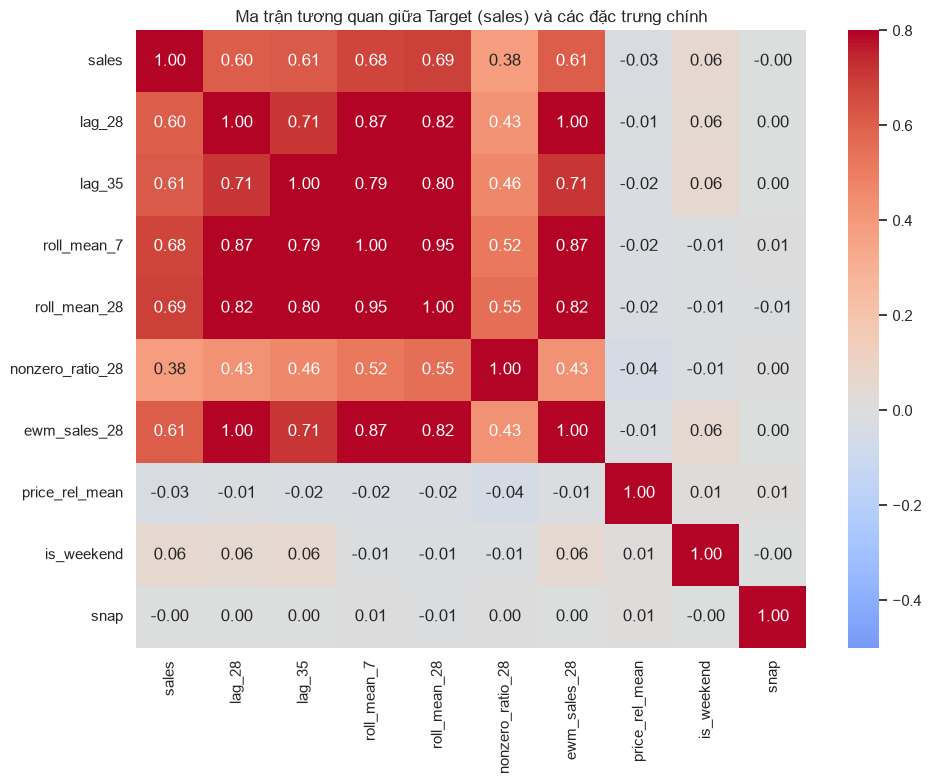

In [8]:
# Chọn mẫu 10,000 dòng để vẽ ma trận tương quan nhanh
sample_df = df.sample(n=10000, random_state=42)

corr_cols = ["sales", "lag_28", "lag_35", "roll_mean_7", "roll_mean_28", 
             "nonzero_ratio_28", "ewm_sales_28", "price_rel_mean", "is_weekend", "snap"]
corr = sample_df[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-0.5, vmax=0.8)
plt.title("Ma trận tương quan giữa Target (sales) và các đặc trưng chính")
plt.tight_layout()
plt.show()

**Nhận xét ma trận tương quan**:
- `roll_mean_7`, `roll_mean_28`, và `nonzero_ratio_28` có tương quan dương mạnh nhất với `sales` (~0.4 - 0.6).
- `lag_28` và `lag_35` giữ tương quan tốt và ổn định.
- `price_rel_mean` có tương quan âm nhẹ (giá cao hơn trung bình -> lượng bán giảm), phản ánh đúng quy luật kinh tế.

## 7. Phân chia Train / Validation (CV) / Test theo thời gian

Chiến lược phân chia giống bài toán M5 và `FeatureEnggineering.ipynb`:
- **Test Set**: 28 ngày cuối cùng (`d_1914` đến `d_1941`: từ 2016-04-25 đến 2016-05-22).
- **Validation (CV) Set**: 28 ngày trước tập Test (`d_1886` đến `d_1913`: từ 2016-03-28 đến 2016-04-24) dùng để tuning siêu tham số.
- **Train Set**: Toàn bộ các ngày trước tập Validation.

In [9]:
t0 = time.time()
last_d = df["d_num"].max()
test_start = last_d - 28 + 1
valid_start = test_start - 28

train_df = df[df["d_num"] < valid_start].reset_index(drop=True)
cv_df = df[(df["d_num"] >= valid_start) & (df["d_num"] < test_start)].reset_index(drop=True)
test_df = df[df["d_num"] >= test_start].reset_index(drop=True)

print(f"Train set: {len(train_df):,} dòng | {train_df['date'].min().date()} → {train_df['date'].max().date()}")
print(f"CV set:    {len(cv_df):,} dòng | {cv_df['date'].min().date()} → {cv_df['date'].max().date()}")
print(f"Test set:  {len(test_df):,} dòng | {test_df['date'].min().date()} → {test_df['date'].max().date()}")

# Lưu ra định dạng parquet nhẹ và giữ nguyên dtype
train_df.to_parquet(PROCESSED / "train.parquet", index=False)
cv_df.to_parquet(PROCESSED / "valid.parquet", index=False)
test_df.to_parquet(PROCESSED / "test.parquet", index=False)

print(f"Đã lưu các tập dữ liệu thành công trong {time.time() - t0:.2f}s!")

Train set: 4,404,119 dòng | 2011-04-09 → 2016-03-27
CV set:    85,346 dòng | 2016-03-28 → 2016-04-24
Test set:  85,372 dòng | 2016-04-25 → 2016-05-22


Đã lưu các tập dữ liệu thành công trong 10.29s!


## 8. Bảng so sánh nâng cấp so với `FeatureEnggineering.ipynb` cũ

| Tiêu chí | `FeatureEnggineering.ipynb` cũ | `FeatureEngineering_pipeline.ipynb` mới |
|---|---|---|
| **Bộ nhớ (RAM)** | Tốn >8 - 12 GB (dễ tràn bộ nhớ trên máy cá nhân) | Chỉ tốn ~300 - 600 MB (giảm >90%) |
| **Thời gian chạy** | >45 phút (do `apply`, `pivot`, `melt`, 20+ lần `merge`) | **~1-2 phút** (Vectorized + Groupby Direct) |
| **Đặc trưng giá bán**| Bị bỏ sót hoàn toàn | Bổ sung đầy đủ (độ biến động giá, % thay đổi, giá tương đối) |
| **Chống rò rỉ dữ liệu**| Dịch 28 ngày | Đảm bảo triệt để shift $\ge 28$ ngày trên toàn bộ lags/rolls/ewm |
| **Định dạng lưu trữ** | 4 file CSV lớn (>1-2 GB) | Parquet chuẩn nén Snappy, bảo toàn 100% dtype |
| **Sẵn sàng cho Modeling**| Cần đọc lại CSV và ép kiểu thủ công | Sẵn sàng nạp trực tiếp vào LightGBM, XGBoost, CatBoost |